# AN6 — Recorded VLE Activity Patterns

**Status:** Local execution evidence is retained for AN0.01 and AN6.01–AN6.04. The first repaired AN6.03 execution completed without the earlier PostgreSQL memory error, but its 500-row retrieval cap truncated the result. A small SQL labeling correction and a higher bounded retrieval limit are now applied. Rerun the notebook cells individually, then execute the Python-only interpretation and reconciliation cells before considering AN6 complete. This notebook measures recorded VLE activity, not learning quality.


## 1. Environment setup

This cell locates the repository and imports the same canonical AN6 execution helpers used by `scripts/run_an6.py`. It does not connect to PostgreSQL.

In [1]:
# 1. Locate the repository and import the canonical AN6 orchestration functions.
from pathlib import Path
import sys
from IPython.display import display

_current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_current, *_current.parents]
        if (candidate / "src" / "analytics" / "db.py").is_file()
        and (candidate / "sql" / "04_analytics").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open Jupyter from the repository root or notebooks folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_an6 import (
    EXPECTED_RESULT_SET_COUNTS as EXPECTED,
    AN6_ANALYTICAL_TIMEOUT_MS,
    verify_read_only_preflight,
    run_an6_query,
    readiness_gate,
)

import pandas as pd
import matplotlib.pyplot as plt

query_results = {}
AN6_READINESS_PASSED = False

print("Project root:", PROJECT_ROOT)
print("Canonical AN6 runner imported: True")
print("AN6 expected result sets:", EXPECTED)


Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
Canonical AN6 runner imported: True
AN6 expected result sets: {'AN6.01': 3, 'AN6.02': 1, 'AN6.03': 1, 'AN6.04': 1}


## 2. AN0.01 — Database identity and read-only preflight

The canonical preflight verifies the intended database and both read-only settings. The returned database identity, session settings, and elapsed time are displayed as execution evidence. No AN6 analytical query runs unless this preflight passes.

In [2]:
# 2. Run the canonical database identity/read-only preflight.
preflight = verify_read_only_preflight()
query_results["PREFLIGHT.AN0.01"] = preflight
display(preflight["data"])
assert preflight["result_set_count"] == 1
print("CONNECTION AND READ-ONLY PREFLIGHT: PASS")



AN6 — PostgreSQL connection and safety preflight
Query: sql\04_analytics\AN0.01_database_identity.sql
Elapsed seconds: 0.057
Returned result sets: 1
  database_name database_user current_schema server_version transaction_read_only default_transaction_read_only statement_timeout lock_timeout
oulad_analytics      postgres         public           18.6                    on                            on              2min           5s
database_name: PASS
transaction_read_only: PASS
default_transaction_read_only: PASS
AN6 PREFLIGHT: PASS — intended database and read-only session confirmed.



,database_name,database_user,current_schema,server_version,transaction_read_only,default_transaction_read_only,statement_timeout,lock_timeout
0,oulad_analytics,postgres,public,18.6,on,on,2min,5s


CONNECTION AND READ-ONLY PREFLIGHT: PASS


## 3. AN6.01 — Readiness and metadata

**Question:** Are all 22 course windows valid, are course-scoped VLE resource keys unique, and are registration/activity keys complete? Review all three result sets. A failed readiness gate blocks AN6.02–AN6.04.

In [3]:
# 3. Execute AN6.01 and validate all three result sets before downstream scans.
r = run_an6_query("AN6.01", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.01"]
query_results["AN6.01"] = r
for item in r["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} displayed rows; truncated={item['display_truncated']}")
    display(item["data"])

AN6_READINESS_PASSED = readiness_gate(r)
print("AN6.01 elapsed seconds:", r["elapsed_seconds"])



AN6.01 | sql\04_analytics\AN6.01_activity_readiness_and_metadata.sql | 24.173 seconds | 3 result set(s) | timeout=120000 ms
Result set 1: 22 displayed row(s); truncated=False
Result set 2: 1 displayed row(s); truncated=False
Result set 3: 1 displayed row(s); truncated=False
Result set 1: 22 displayed rows; truncated=False


,code_module,code_presentation,module_presentation_length,course_key_rows,valid_course_window
0,AAA,2013J,268,1,True
1,AAA,2014J,269,1,True
2,BBB,2013B,240,1,True
3,BBB,2013J,268,1,True
4,BBB,2014B,234,1,True
5,BBB,2014J,262,1,True
6,CCC,2014B,241,1,True
7,CCC,2014J,269,1,True
8,DDD,2013B,240,1,True
9,DDD,2013J,261,1,True


Result set 2: 1 displayed rows; truncated=False


,vle_rows,distinct_resource_keys,duplicate_resource_keys,excess_rows_over_distinct_resource_keys,null_resource_key_component_rows,missing_activity_type_rows,missing_week_from_rows,missing_week_to_rows,reversed_week_range_rows
0,6364,6364,0,0,0,0,5243,5243,0


Result set 3: 1 displayed rows; truncated=False


,registration_rows,distinct_registration_keys,duplicate_registration_keys,excess_registration_rows,registration_keys_without_course_window,activity_rows,activity_rows_with_null_key_component,activity_rows_without_course_window
0,32593,32593,0,0,0,10655280,0,0


AN6.01 — readiness checks
expected_22_course_presentations: PASS
valid_course_windows: PASS
unique_course_keys: PASS
unique_course_scoped_vle_resource_keys: PASS
complete_vle_resource_key_components: PASS
unique_registration_keys: PASS
registration_course_matches: PASS
complete_student_vle_key_components: PASS
student_vle_course_window_matches: PASS
Metadata completeness diagnostics (reported, not used as filters): [{'missing_activity_type_rows': 0, 'missing_week_from_rows': 5243, 'missing_week_to_rows': 5243, 'reversed_week_range_rows': 0}]
AN6.01 READINESS: PASS — downstream queries are unlocked.

AN6.01 elapsed seconds: 24.173


## 4. AN6.02 — In-course coverage and student-presentation distributions

**Question:** What share of registered student-presentations has in-course activity? How are zero-inclusive active days and resource breadth distributed? First activity day is conditional on activity being recorded.


In [4]:
# Execute AN6.02 only after the AN6.01 readiness gate has passed.
assert AN6_READINESS_PASSED, 'Run and pass the AN6.01 readiness gate before this query.'
r = run_an6_query("AN6.02", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.02"]
query_results["AN6.02"] = r
display(r["result_sets"][0]["data"])
print("Elapsed seconds:", r["elapsed_seconds"])



AN6.02 | sql\04_analytics\AN6.02_in_course_student_presentation_metrics.sql | 124.895 seconds | 1 result set(s) | timeout=600000 ms
Result set 1: 88 displayed row(s); truncated=False


,code_module,code_presentation,output_section,metric,registered_denominator,observed_count,outside_window_only_count,no_recorded_activity_count,pct_or_mean,p25,median,p75,p90
0,AAA,2013J,COVERAGE,IN_COURSE_COVERAGE,383,376,2.0,5.0,98.17,NaN,NaN,NaN,NaN
1,AAA,2013J,DISTRIBUTION,ACTIVE_DAYS,383,7,NaN,NaN,84.7389033942558747,38.5,76.0,119.5,169.0
2,AAA,2013J,DISTRIBUTION,FIRST_IN_COURSE_DAY,383,376,2.0,5.0,2.4574468085106383,0.0,1.0,3.0,7.0
3,AAA,2013J,DISTRIBUTION,RESOURCE_BREADTH,383,7,NaN,NaN,58.8511749347258486,42.5,60.0,78.0,87.0
4,AAA,2014J,COVERAGE,IN_COURSE_COVERAGE,365,352,5.0,8.0,96.44,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,GGG,2014B,DISTRIBUTION,RESOURCE_BREADTH,833,67,NaN,NaN,27.6770708283313325,14.0,29.0,41.0,49.0
84,GGG,2014J,COVERAGE,IN_COURSE_COVERAGE,749,689,9.0,51.0,91.99,NaN,NaN,NaN,NaN
85,GGG,2014J,DISTRIBUTION,ACTIVE_DAYS,749,60,NaN,NaN,32.2603471295060080,8.0,27.0,46.0,68.0
86,GGG,2014J,DISTRIBUTION,FIRST_IN_COURSE_DAY,749,689,9.0,51.0,9.2119013062409289,1.0,3.0,9.0,25.0


Elapsed seconds: 124.895


## 5. AN6.03 — Temporal patterns

**Question:** How do recorded activity rows distribute across PRE/IN/POST and fixed seven-day bins? These bins are analytical periods, not academic weeks.

**Execution design:** The SQL pre-aggregates to student-presentation × temporal bucket/period grain using GROUPING SETS, avoiding the large composite distinct-key sort and final global sort that caused the first execution failure.

**First repaired execution evidence:** AN6.03 completed in 94.658 seconds without the previous OutOfMemory error, but the runner returned 500 rows with truncation. This proves that the memory-pressure redesign executed; it does not establish that the temporal output is complete.

**Follow-up correction:** Period labels now preserve the temporal class (IN_COURSE_PERIOD_### versus POST_COURSE_PERIOD_###). Previously, a seven-day bin spanning the course end could produce two rows with the same visible label. Empty unmatched-registration period counts are also normalized to zero.


In [5]:
# Execute AN6.03 after the readiness gate; retrieve enough rows for full reconciliation.
assert AN6_READINESS_PASSED, 'Run and pass the AN6.01 readiness gate before this query.'
r = run_an6_query("AN6.03", max_rows=2000, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.03"]
query_results["AN6.03"] = r
for item in r["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} displayed rows; truncated={item['display_truncated']}")
display(r["result_sets"][0]["data"])
print("Elapsed seconds:", r["elapsed_seconds"])



AN6.03 | sql\04_analytics\AN6.03_relative_time_patterns.sql | 145.074 seconds | 1 result set(s) | timeout=600000 ms
Result set 1: 971 displayed row(s); truncated=False
Result set 1: 971 displayed rows; truncated=False


,code_module,code_presentation,output_section,bucket_label,period_index,registered_student_presentations,activity_rows,active_registered_student_presentations,unmatched_registration_activity_rows,recorded_clicks
0,AAA,2013J,TEMPORAL_BUCKET,IN_COURSE,NaN,383,170135,376,0.0,598871
1,AAA,2013J,TEMPORAL_BUCKET,PRE_COURSE,NaN,383,10847,352,0.0,49623
2,AAA,2014J,TEMPORAL_BUCKET,IN_COURSE,NaN,365,154808,352,0.0,534312
3,AAA,2014J,TEMPORAL_BUCKET,PRE_COURSE,NaN,365,14508,335,0.0,63846
4,BBB,2013B,TEMPORAL_BUCKET,IN_COURSE,NaN,1767,383528,1513,0.0,1282887
...,...,...,...,...,...,...,...,...,...,...
966,GGG,2014B,BOUNDARY_DIAGNOSTIC,LAST_IN_COURSE_DAY,NaN,833,31,24,0.0,44
967,GGG,2014J,BOUNDARY_DIAGNOSTIC,DAY_MINUS_1,NaN,749,717,135,0.0,2162
968,GGG,2014J,BOUNDARY_DIAGNOSTIC,DAY_ZERO,NaN,749,1022,156,0.0,2948
969,GGG,2014J,BOUNDARY_DIAGNOSTIC,FIRST_POST_COURSE_DAY,NaN,749,0,0,0.0,None


Elapsed seconds: 145.074


## 6. AN6.04 — Activity-type composition

**Question:** Which resource types contribute to in-course resource breadth and registered student-presentation reach? Missing and unmatched metadata remain explicit.


In [7]:
# Execute AN6.04 only after the AN6.01 readiness gate has passed.
assert AN6_READINESS_PASSED, 'Run and pass the AN6.01 readiness gate before this query.'
r = run_an6_query("AN6.04", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.04"]
query_results["AN6.04"] = r
display(r["result_sets"][0]["data"])
print("Elapsed seconds:", r["elapsed_seconds"])



AN6.04 | sql\04_analytics\AN6.04_activity_type_resource_patterns.sql | 128.551 seconds | 1 result set(s) | timeout=600000 ms
Result set 1: 254 displayed row(s); truncated=False


,output_section,code_module,code_presentation,activity_type,registered_student_presentations,in_course_activity_rows,distinct_resources,active_student_presentations,registered_reach_pct,distinct_course_relative_days,unmatched_resource_rows,all_activity_rows,matched_resource_rows,unmatched_resource_rows_total,missing_activity_type_rows,unmatched_registration_activity_rows
0,ALL_ACTIVITY_METADATA_MATCH,AAA,2013J,ALL_TYPES,383,NaN,NaN,NaN,None,NaN,NaN,180982.0,180982.0,0.0,0.0,0.0
1,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,dataplus,383,442.0,4.0,190.0,49.61,149.0,0.0,NaN,NaN,NaN,NaN,NaN
2,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,forumng,383,55083.0,15.0,371.0,96.87,269.0,0.0,NaN,NaN,NaN,NaN,NaN
3,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,glossary,383,102.0,2.0,60.0,15.67,76.0,0.0,NaN,NaN,NaN,NaN,NaN
4,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,homepage,383,31836.0,1.0,376.0,98.17,269.0,0.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,homepage,749,22710.0,1.0,688.0,91.86,270.0,0.0,NaN,NaN,NaN,NaN,NaN
250,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,oucontent,749,26634.0,26.0,656.0,87.58,248.0,0.0,NaN,NaN,NaN,NaN,NaN
251,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,quiz,749,18899.0,8.0,582.0,77.70,237.0,0.0,NaN,NaN,NaN,NaN,NaN
252,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,resource,749,13475.0,61.0,676.0,90.25,252.0,0.0,NaN,NaN,NaN,NaN,NaN


Elapsed seconds: 128.551


## 7. Descriptive visual summary

Charts are created only from returned SQL frames; no pre-execution figures or findings are embedded.


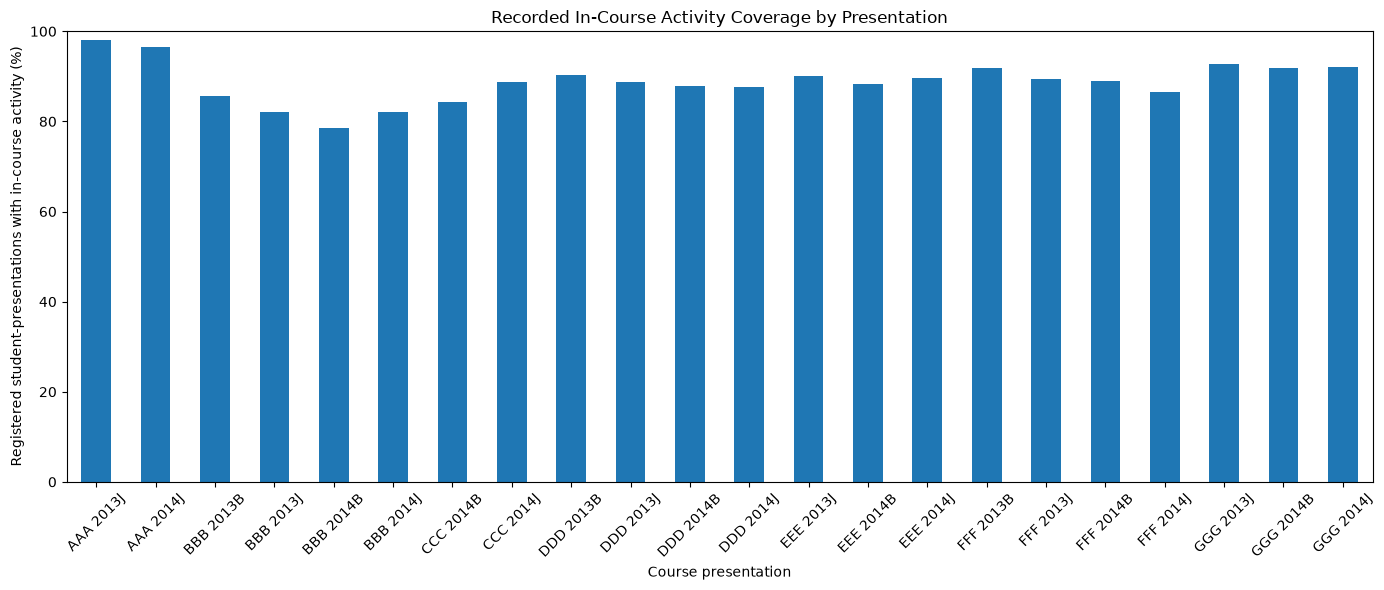

,code_module,code_presentation,output_section,metric,registered_denominator,observed_count,outside_window_only_count,no_recorded_activity_count,pct_or_mean,p25,median,p75,p90
1,AAA,2013J,DISTRIBUTION,ACTIVE_DAYS,383,7,NaN,NaN,84.7389033942558747,38.5,76.0,119.5,169.0
2,AAA,2013J,DISTRIBUTION,FIRST_IN_COURSE_DAY,383,376,2.0,5.0,2.4574468085106383,0.0,1.0,3.0,7.0
3,AAA,2013J,DISTRIBUTION,RESOURCE_BREADTH,383,7,NaN,NaN,58.8511749347258486,42.5,60.0,78.0,87.0
5,AAA,2014J,DISTRIBUTION,ACTIVE_DAYS,365,13,NaN,NaN,77.2109589041095890,31.0,64.0,117.0,154.6
6,AAA,2014J,DISTRIBUTION,FIRST_IN_COURSE_DAY,365,352,5.0,8.0,2.9346590909090909,0.0,2.0,4.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,GGG,2014B,DISTRIBUTION,FIRST_IN_COURSE_DAY,833,766,7.0,60.0,8.3289817232375979,1.0,3.0,9.0,23.0
83,GGG,2014B,DISTRIBUTION,RESOURCE_BREADTH,833,67,NaN,NaN,27.6770708283313325,14.0,29.0,41.0,49.0
85,GGG,2014J,DISTRIBUTION,ACTIVE_DAYS,749,60,NaN,NaN,32.2603471295060080,8.0,27.0,46.0,68.0
86,GGG,2014J,DISTRIBUTION,FIRST_IN_COURSE_DAY,749,689,9.0,51.0,9.2119013062409289,1.0,3.0,9.0,25.0


In [8]:
# 1. Plot in-course activity coverage using an explicitly numeric series.
if "AN6.02" in query_results:
    frame = query_results["AN6.02"]["result_sets"][0]["data"].copy()

    cov = frame.loc[
        frame["output_section"].eq("COVERAGE")
    ].copy()

    if not cov.empty:
        # PostgreSQL NUMERIC values may arrive as Decimal/object in pandas.
        cov["coverage_pct"] = pd.to_numeric(
            cov["pct_or_mean"],
            errors="coerce"
        )

        # Verify that all expected coverage values are numeric.
        invalid_values = cov["coverage_pct"].isna().sum()

        if invalid_values:
            raise ValueError(
                f"AN6.02 coverage contains {invalid_values} "
                "missing or non-numeric percentage values."
            )

        cov["presentation"] = (
            cov["code_module"].astype(str)
            + " "
            + cov["code_presentation"].astype(str)
        )

        cov = cov.sort_values(
            ["code_module", "code_presentation"]
        )

        ax = cov.plot(
            x="presentation",
            y="coverage_pct",
            kind="bar",
            legend=False,
            figsize=(14, 6),
            title="Recorded In-Course Activity Coverage by Presentation"
        )

        ax.set_ylabel(
            "Registered student-presentations with in-course activity (%)"
        )
        ax.set_xlabel("Course presentation")
        ax.set_ylim(0, 100)
        ax.tick_params(axis="x", rotation=45)

        plt.tight_layout()
        plt.show()

    # Display the zero-inclusive distributions.
    distributions = frame.loc[
        frame["output_section"].eq("DISTRIBUTION")
    ].copy()

    display(distributions)

## 8. Review checklist

- Confirm all four canonical query IDs returned their expected result-set counts.
- AN6.03 must have display_truncated=False; the Python review cells stop if its result is incomplete.
- Reconcile temporal bucket totals against relative-period totals and AN6.02 in-course reach.
- Reconcile AN6.04 metadata totals against AN6.01 source-row counts and AN6.03 registered/unmatched activity.
- Interpret the fixed registered cohort as a descriptive population, not an at-risk survival cohort.
- Do not interpret missing VLE rows as absence of learning, resource breadth as time spent, or click volume as a primary KPI.
- AN6 does not approve a composite score, threshold, outcome association, causal claim, predictive feature, or intervention.


## 9. AN6.02 — Coverage and distribution interpretation

This review uses the complete in-memory AN6.02 result frame, not the abbreviated pandas display. It reports pooled coverage using the sum of presentation numerators and denominators, verifies that coverage/outside-only/no-recorded-activity states partition the registered cohort, and keeps zero-inclusive distributions separate from first-activity timing.

In [9]:
# 9. Summarize all AN6.02 presentations and verify the registered-population partition.
an602_item = query_results["AN6.02"]["result_sets"][0]
if an602_item["display_truncated"]:
    raise RuntimeError("AN6.02 is truncated; do not interpret incomplete coverage or distributions.")

an602_df = an602_item["data"].copy()
an602_keys = ["code_module", "code_presentation"]
an602_coverage = an602_df.loc[an602_df["output_section"].eq("COVERAGE")].copy()
assert len(an602_coverage) == 22
assert not an602_coverage.duplicated(an602_keys).any()

for col in ["registered_denominator", "observed_count", "outside_window_only_count",
            "no_recorded_activity_count", "pct_or_mean"]:
    an602_coverage[col] = pd.to_numeric(an602_coverage[col], errors="coerce")

an602_coverage["state_total"] = (
    an602_coverage["observed_count"]
    + an602_coverage["outside_window_only_count"].fillna(0)
    + an602_coverage["no_recorded_activity_count"].fillna(0)
)
an602_coverage["partition_pass"] = (
    an602_coverage["state_total"] == an602_coverage["registered_denominator"]
)
AN6_02_PARTITION_PASSED = bool(an602_coverage["partition_pass"].all())

coverage_denominator = int(an602_coverage["registered_denominator"].sum())
coverage_numerator = int(an602_coverage["observed_count"].sum())
outside_only_total = int(an602_coverage["outside_window_only_count"].fillna(0).sum())
no_activity_total = int(an602_coverage["no_recorded_activity_count"].fillna(0).sum())
pooled_coverage_pct = 100.0 * coverage_numerator / coverage_denominator

display(an602_coverage[
    an602_keys + ["observed_count", "registered_denominator", "pct_or_mean",
                  "outside_window_only_count", "no_recorded_activity_count", "partition_pass"]
].sort_values(an602_keys))

print("Registered student-presentations:", coverage_denominator)
print("With in-course recorded activity:", coverage_numerator)
print("Pooled in-course coverage (%):", round(pooled_coverage_pct, 2))
print("Outside-window-only:", outside_only_total)
print("No recorded activity:", no_activity_total)
print("Coverage-state partition:", "PASS" if AN6_02_PARTITION_PASSED else "FAIL")

an602_distribution = an602_df.loc[
    an602_df["output_section"].eq("DISTRIBUTION")
].copy()
for col in ["pct_or_mean", "p25", "median", "p75", "p90",
            "registered_denominator", "observed_count"]:
    an602_distribution[col] = pd.to_numeric(an602_distribution[col], errors="coerce")
display(an602_distribution[
    an602_keys + ["metric", "registered_denominator", "observed_count",
                  "pct_or_mean", "p25", "median", "p75", "p90"]
].sort_values(an602_keys + ["metric"]))

print("Interpretation: ACTIVE_DAYS and RESOURCE_BREADTH retain zero-activity registrations.")
print("FIRST_IN_COURSE_DAY quantiles describe only registrations with a recorded in-course first day; observed_count is the conditional population.")


,code_module,code_presentation,observed_count,registered_denominator,pct_or_mean,outside_window_only_count,no_recorded_activity_count,partition_pass
0,AAA,2013J,376,383,98.17,2.0,5.0,True
4,AAA,2014J,352,365,96.44,5.0,8.0,True
8,BBB,2013B,1513,1767,85.63,24.0,230.0,True
12,BBB,2013J,1836,2237,82.07,34.0,367.0,True
16,BBB,2014B,1266,1613,78.49,28.0,319.0,True
20,BBB,2014J,1880,2292,82.02,41.0,371.0,True
24,CCC,2014B,1631,1936,84.25,50.0,255.0,True
28,CCC,2014J,2215,2498,88.67,87.0,196.0,True
32,DDD,2013B,1178,1303,90.41,36.0,89.0,True
36,DDD,2013J,1722,1938,88.85,46.0,170.0,True


Registered student-presentations: 32593
With in-course recorded activity: 28500
Pooled in-course coverage (%): 87.44
Outside-window-only: 728
No recorded activity: 3365
Coverage-state partition: PASS


,code_module,code_presentation,metric,registered_denominator,observed_count,pct_or_mean,p25,median,p75,p90
1,AAA,2013J,ACTIVE_DAYS,383,7,84.738903,38.5,76.0,119.5,169.0
2,AAA,2013J,FIRST_IN_COURSE_DAY,383,376,2.457447,0.0,1.0,3.0,7.0
3,AAA,2013J,RESOURCE_BREADTH,383,7,58.851175,42.5,60.0,78.0,87.0
5,AAA,2014J,ACTIVE_DAYS,365,13,77.210959,31.0,64.0,117.0,154.6
6,AAA,2014J,FIRST_IN_COURSE_DAY,365,352,2.934659,0.0,2.0,4.0,8.0
...,...,...,...,...,...,...,...,...,...,...
82,GGG,2014B,FIRST_IN_COURSE_DAY,833,766,8.328982,1.0,3.0,9.0,23.0
83,GGG,2014B,RESOURCE_BREADTH,833,67,27.677071,14.0,29.0,41.0,49.0
85,GGG,2014J,ACTIVE_DAYS,749,60,32.260347,8.0,27.0,46.0,68.0
86,GGG,2014J,FIRST_IN_COURSE_DAY,749,689,9.211901,1.0,3.0,9.0,25.0


Interpretation: ACTIVE_DAYS and RESOURCE_BREADTH retain zero-activity registrations.
FIRST_IN_COURSE_DAY quantiles describe only registrations with a recorded in-course first day; observed_count is the conditional population.


## 10. AN6.03 — Temporal interpretation and reconciliation

The temporal summary is accepted only when the full result set is retrieved. This cell tests four relationships: bucket totals equal relative-period totals per presentation; both reconcile to the AN6.01 activity-row count; registered in-course reach matches AN6.02 on the student-presentation grain; and four boundary-day diagnostics exist for every presentation.

PRE/IN/POST reach values are not mutually exclusive: one registered student-presentation may have activity in several temporal classes or periods.

In [10]:
# 10. Reconcile the complete AN6.03 temporal output with AN6.01 and AN6.02.
an603_item = query_results["AN6.03"]["result_sets"][0]
if an603_item["display_truncated"]:
    raise RuntimeError("AN6.03 remains truncated. Increase max_rows and rerun AN6.03.")

an603_df = an603_item["data"].copy()
an603_keys = ["code_module", "code_presentation"]
for col in ["period_index", "registered_student_presentations", "activity_rows",
            "active_registered_student_presentations",
            "unmatched_registration_activity_rows", "recorded_clicks"]:
    an603_df[col] = pd.to_numeric(an603_df[col], errors="coerce")

an603_bucket = an603_df.loc[an603_df["output_section"].eq("TEMPORAL_BUCKET")].copy()
an603_period = an603_df.loc[an603_df["output_section"].eq("RELATIVE_7DAY_PERIOD")].copy()
an603_boundary = an603_df.loc[an603_df["output_section"].eq("BOUNDARY_DIAGNOSTIC")].copy()

bucket_totals = an603_bucket.groupby(an603_keys, as_index=False).agg(
    bucket_activity_rows=("activity_rows", "sum"),
    bucket_unmatched_rows=("unmatched_registration_activity_rows", "sum")
)
period_totals = an603_period.groupby(an603_keys, as_index=False).agg(
    period_activity_rows=("activity_rows", "sum"),
    period_unmatched_rows=("unmatched_registration_activity_rows", "sum")
)
temporal_reconciliation = bucket_totals.merge(
    period_totals, on=an603_keys, how="outer", validate="one_to_one"
)
temporal_reconciliation["activity_rows_match"] = (
    temporal_reconciliation["bucket_activity_rows"]
    == temporal_reconciliation["period_activity_rows"]
)
temporal_reconciliation["unmatched_rows_match"] = (
    temporal_reconciliation["bucket_unmatched_rows"].fillna(0)
    == temporal_reconciliation["period_unmatched_rows"].fillna(0)
)

an601_activity_rows = int(
    query_results["AN6.01"]["result_sets"][2]["data"].iloc[0]["activity_rows"]
)
bucket_activity_total = int(an603_bucket["activity_rows"].sum())
period_activity_total = int(an603_period["activity_rows"].sum())

an602_cov = an602_coverage[
    an603_keys + ["registered_denominator", "observed_count"]
].copy()
an603_in_course = an603_bucket.loc[
    an603_bucket["bucket_label"].eq("IN_COURSE"),
    an603_keys + ["registered_student_presentations",
                  "active_registered_student_presentations"]
].copy()
reach_reconciliation = an602_cov.merge(
    an603_in_course, on=an603_keys, how="left", validate="one_to_one"
)
reach_reconciliation["registered_student_presentations"] = (
    reach_reconciliation["registered_student_presentations"]
    .fillna(reach_reconciliation["registered_denominator"])
)
reach_reconciliation["active_registered_student_presentations"] = (
    reach_reconciliation["active_registered_student_presentations"].fillna(0)
)
reach_reconciliation["denominator_match"] = (
    reach_reconciliation["registered_denominator"]
    == reach_reconciliation["registered_student_presentations"]
)
reach_reconciliation["in_course_reach_match"] = (
    reach_reconciliation["observed_count"]
    == reach_reconciliation["active_registered_student_presentations"]
)

boundary_counts = an603_boundary.groupby(an603_keys, as_index=False).agg(
    boundary_rows=("bucket_label", "count"),
    distinct_boundary_labels=("bucket_label", "nunique")
)
boundary_pass = (
    len(an603_boundary) == 88
    and bool((boundary_counts["boundary_rows"] == 4).all())
    and bool((boundary_counts["distinct_boundary_labels"] == 4).all())
)
temporal_pass = (
    bool(temporal_reconciliation["activity_rows_match"].all())
    and bool(temporal_reconciliation["unmatched_rows_match"].all())
    and bucket_activity_total == an601_activity_rows
    and period_activity_total == an601_activity_rows
)
reach_pass = (
    bool(reach_reconciliation["denominator_match"].all())
    and bool(reach_reconciliation["in_course_reach_match"].all())
)
AN6_03_RECONCILIATION_PASSED = bool(temporal_pass and reach_pass and boundary_pass)

display(temporal_reconciliation.sort_values(an603_keys))
display(reach_reconciliation.sort_values(an603_keys))
display(an603_bucket.sort_values(an603_keys + ["bucket_label"]))
display(an603_boundary.sort_values(an603_keys + ["bucket_label"]))

print("AN6.01 source activity rows:", an601_activity_rows)
print("AN6.03 temporal-bucket activity rows:", bucket_activity_total)
print("AN6.03 relative-period activity rows:", period_activity_total)
print("Temporal bucket/period reconciliation:", "PASS" if temporal_pass else "FAIL")
print("AN6.02/AN6.03 denominator and in-course reach:", "PASS" if reach_pass else "FAIL")
print("Boundary diagnostics (88 rows; four per presentation):", "PASS" if boundary_pass else "FAIL")
print("AN6.03 reconciliation:", "PASS" if AN6_03_RECONCILIATION_PASSED else "FAIL")
print("Temporal classes:", sorted(an603_bucket["bucket_label"].dropna().unique().tolist()))
print("Relative-period labels:", sorted(an603_period["bucket_label"].dropna().unique().tolist()))
print("PRE/IN/POST registered reach is overlapping and must not be summed as unique students.")


,code_module,code_presentation,bucket_activity_rows,bucket_unmatched_rows,period_activity_rows,period_unmatched_rows,activity_rows_match,unmatched_rows_match
0,AAA,2013J,180982,0.0,180982,0.0,True,True
1,AAA,2014J,169316,0.0,169316,0.0,True,True
2,BBB,2013B,403266,0.0,403266,0.0,True,True
3,BBB,2013J,452638,0.0,452638,0.0,True,True
4,BBB,2014B,273236,0.0,273236,0.0,True,True
5,BBB,2014J,438424,0.0,438424,0.0,True,True
6,CCC,2014B,496181,0.0,496181,0.0,True,True
7,CCC,2014J,711646,0.0,711646,0.0,True,True
8,DDD,2013B,536837,0.0,536837,0.0,True,True
9,DDD,2013J,680806,0.0,680806,0.0,True,True


,code_module,code_presentation,registered_denominator,observed_count,registered_student_presentations,active_registered_student_presentations,denominator_match,in_course_reach_match
0,AAA,2013J,383,376,383,376,True,True
1,AAA,2014J,365,352,365,352,True,True
2,BBB,2013B,1767,1513,1767,1513,True,True
3,BBB,2013J,2237,1836,2237,1836,True,True
4,BBB,2014B,1613,1266,1613,1266,True,True
5,BBB,2014J,2292,1880,2292,1880,True,True
6,CCC,2014B,1936,1631,1936,1631,True,True
7,CCC,2014J,2498,2215,2498,2215,True,True
8,DDD,2013B,1303,1178,1303,1178,True,True
9,DDD,2013J,1938,1722,1938,1722,True,True


,code_module,code_presentation,output_section,bucket_label,period_index,registered_student_presentations,activity_rows,active_registered_student_presentations,unmatched_registration_activity_rows,recorded_clicks
0,AAA,2013J,TEMPORAL_BUCKET,IN_COURSE,NaN,383,170135,376,0.0,598871.0
1,AAA,2013J,TEMPORAL_BUCKET,PRE_COURSE,NaN,383,10847,352,0.0,49623.0
2,AAA,2014J,TEMPORAL_BUCKET,IN_COURSE,NaN,365,154808,352,0.0,534312.0
3,AAA,2014J,TEMPORAL_BUCKET,PRE_COURSE,NaN,365,14508,335,0.0,63846.0
4,BBB,2013B,TEMPORAL_BUCKET,IN_COURSE,NaN,1767,383528,1513,0.0,1282887.0
5,BBB,2013B,TEMPORAL_BUCKET,PRE_COURSE,NaN,1767,19738,1093,0.0,65024.0
6,BBB,2013J,TEMPORAL_BUCKET,IN_COURSE,NaN,2237,432812,1836,0.0,1315132.0
7,BBB,2013J,TEMPORAL_BUCKET,PRE_COURSE,NaN,2237,19826,1351,0.0,63524.0
8,BBB,2014B,TEMPORAL_BUCKET,IN_COURSE,NaN,1613,261336,1266,0.0,796264.0
9,BBB,2014B,TEMPORAL_BUCKET,PRE_COURSE,NaN,1613,11900,902,0.0,37601.0


,code_module,code_presentation,output_section,bucket_label,period_index,registered_student_presentations,activity_rows,active_registered_student_presentations,unmatched_registration_activity_rows,recorded_clicks
883,AAA,2013J,BOUNDARY_DIAGNOSTIC,DAY_MINUS_1,NaN,383,691,131,0.0,2836.0
884,AAA,2013J,BOUNDARY_DIAGNOSTIC,DAY_ZERO,NaN,383,1205,143,0.0,4611.0
885,AAA,2013J,BOUNDARY_DIAGNOSTIC,FIRST_POST_COURSE_DAY,NaN,383,0,0,0.0,NaN
886,AAA,2013J,BOUNDARY_DIAGNOSTIC,LAST_IN_COURSE_DAY,NaN,383,74,44,0.0,118.0
887,AAA,2014J,BOUNDARY_DIAGNOSTIC,DAY_MINUS_1,NaN,365,572,114,0.0,2809.0
...,...,...,...,...,...,...,...,...,...,...
966,GGG,2014B,BOUNDARY_DIAGNOSTIC,LAST_IN_COURSE_DAY,NaN,833,31,24,0.0,44.0
967,GGG,2014J,BOUNDARY_DIAGNOSTIC,DAY_MINUS_1,NaN,749,717,135,0.0,2162.0
968,GGG,2014J,BOUNDARY_DIAGNOSTIC,DAY_ZERO,NaN,749,1022,156,0.0,2948.0
969,GGG,2014J,BOUNDARY_DIAGNOSTIC,FIRST_POST_COURSE_DAY,NaN,749,0,0,0.0,NaN


AN6.01 source activity rows: 10655280
AN6.03 temporal-bucket activity rows: 10655280
AN6.03 relative-period activity rows: 10655280
Temporal bucket/period reconciliation: PASS
AN6.02/AN6.03 denominator and in-course reach: PASS
Boundary diagnostics (88 rows; four per presentation): PASS
AN6.03 reconciliation: PASS
Temporal classes: ['IN_COURSE', 'PRE_COURSE']
Relative-period labels: ['PERIOD_000', 'PERIOD_001', 'PERIOD_002', 'PERIOD_003', 'PERIOD_004', 'PERIOD_005', 'PERIOD_006', 'PERIOD_007', 'PERIOD_008', 'PERIOD_009', 'PERIOD_010', 'PERIOD_011', 'PERIOD_012', 'PERIOD_013', 'PERIOD_014', 'PERIOD_015', 'PERIOD_016', 'PERIOD_017', 'PERIOD_018', 'PERIOD_019', 'PERIOD_020', 'PERIOD_021', 'PERIOD_022', 'PERIOD_023', 'PERIOD_024', 'PERIOD_025', 'PERIOD_026', 'PERIOD_027', 'PERIOD_028', 'PERIOD_029', 'PERIOD_030', 'PERIOD_031', 'PERIOD_032', 'PERIOD_033', 'PERIOD_034', 'PERIOD_035', 'PERIOD_036', 'PERIOD_037', 'PERIOD_038', 'PRE_COURSE']
PRE/IN/POST registered reach is overlapping and must 

## 11. AN6.04 — Activity-type and metadata interpretation

The metadata reconciliation rows describe **all recorded activity dates**, whereas activity-type rows describe **registered in-course activity only**. The two output sections have different time/population scopes.

The review verifies that all-activity rows reconcile to AN6.01, matched and unmatched resource rows partition the activity population, unmatched-registration rows reconcile to AN6.03, and in-course activity-type rows reconcile after excluding unmatched registrations. Activity-type reach is non-additive because one student-presentation may use multiple types.

In [11]:
# 11. Summarize the full AN6.04 frame and reconcile its two output sections.
an604_item = query_results["AN6.04"]["result_sets"][0]
if an604_item["display_truncated"]:
    raise RuntimeError("AN6.04 is truncated; do not interpret incomplete activity-type output.")

an604_df = an604_item["data"].copy()
an604_meta = an604_df.loc[
    an604_df["output_section"].eq("ALL_ACTIVITY_METADATA_MATCH")
].copy()
an604_types = an604_df.loc[
    an604_df["output_section"].eq("IN_COURSE_ACTIVITY_TYPE")
].copy()
assert len(an604_meta) == 22
assert not an604_meta.duplicated(an603_keys).any()

for col in ["all_activity_rows", "matched_resource_rows", "unmatched_resource_rows_total",
            "missing_activity_type_rows", "unmatched_registration_activity_rows"]:
    an604_meta[col] = pd.to_numeric(an604_meta[col], errors="coerce")
for col in ["in_course_activity_rows", "distinct_resources", "active_student_presentations",
            "registered_reach_pct", "distinct_course_relative_days", "unmatched_resource_rows"]:
    an604_types[col] = pd.to_numeric(an604_types[col], errors="coerce")

source_activity_rows = int(
    query_results["AN6.01"]["result_sets"][2]["data"].iloc[0]["activity_rows"]
)
metadata_all_rows = int(an604_meta["all_activity_rows"].sum())
metadata_matched_rows = int(an604_meta["matched_resource_rows"].sum())
metadata_unmatched_rows = int(an604_meta["unmatched_resource_rows_total"].sum())
metadata_unmatched_registration_rows = int(
    an604_meta["unmatched_registration_activity_rows"].sum()
)
metadata_missing_type_rows = int(an604_meta["missing_activity_type_rows"].sum())
temporal_unmatched_rows = int(
    an603_bucket["unmatched_registration_activity_rows"].sum()
)

an604_type_totals = an604_types.groupby(an603_keys, as_index=False).agg(
    registered_in_course_activity_rows=("in_course_activity_rows", "sum")
)
an603_in_course_rows = an603_bucket.loc[
    an603_bucket["bucket_label"].eq("IN_COURSE"),
    an603_keys + ["activity_rows", "unmatched_registration_activity_rows"]
].copy()
an603_registered_rows = an603_in_course_rows.assign(
    expected_registered_in_course_rows=lambda x:
        x["activity_rows"].fillna(0)
        - x["unmatched_registration_activity_rows"].fillna(0)
)
type_reconciliation = an603_registered_rows[
    an603_keys + ["expected_registered_in_course_rows"]
].merge(an604_type_totals, on=an603_keys, how="outer", validate="one_to_one")
type_reconciliation["registered_rows_match"] = (
    type_reconciliation["expected_registered_in_course_rows"].fillna(0)
    == type_reconciliation["registered_in_course_activity_rows"].fillna(0)
)

metadata_pass = (
    metadata_all_rows == source_activity_rows
    and metadata_matched_rows + metadata_unmatched_rows == metadata_all_rows
    and metadata_missing_type_rows == 0
    and metadata_unmatched_registration_rows == temporal_unmatched_rows
)
type_pass = bool(type_reconciliation["registered_rows_match"].all())
AN6_04_RECONCILIATION_PASSED = bool(metadata_pass and type_pass)

display(an604_meta.sort_values(an603_keys))
display(type_reconciliation.sort_values(an603_keys))

an604_type_profile = (
    an604_types.groupby("activity_type", dropna=False, as_index=False)
    .agg(
        in_course_activity_rows=("in_course_activity_rows", "sum"),
        presentation_type_rows=("activity_type", "size"),
        resources_summed_across_presentations=("distinct_resources", "sum"),
        registered_student_presentations_summed_across_presentations=("active_student_presentations", "sum"),
        mean_presentation_reach_pct=("registered_reach_pct", "mean"),
        unmatched_resource_rows=("unmatched_resource_rows", "sum")
    )
    .sort_values("in_course_activity_rows", ascending=False)
)
display(an604_type_profile)

print("All activity rows:", metadata_all_rows, "| AN6.01 source rows:", source_activity_rows)
print("Resource rows — matched:", metadata_matched_rows, "| unmatched:", metadata_unmatched_rows)
print("Activity rows with missing activity_type:", metadata_missing_type_rows)
print("Unmatched-registration rows — AN6.04:", metadata_unmatched_registration_rows,
      "| AN6.03:", temporal_unmatched_rows)
print("Registered in-course activity-type reconciliation:", "PASS" if type_pass else "FAIL")
print("AN6.04 reconciliation:", "PASS" if AN6_04_RECONCILIATION_PASSED else "FAIL")
print("Reach across activity types is non-additive; resource sums are presentation-level, not globally deduplicated.")


,output_section,code_module,code_presentation,activity_type,registered_student_presentations,in_course_activity_rows,distinct_resources,active_student_presentations,registered_reach_pct,distinct_course_relative_days,unmatched_resource_rows,all_activity_rows,matched_resource_rows,unmatched_resource_rows_total,missing_activity_type_rows,unmatched_registration_activity_rows
0,ALL_ACTIVITY_METADATA_MATCH,AAA,2013J,ALL_TYPES,383,NaN,NaN,NaN,None,NaN,NaN,180982.0,180982.0,0.0,0.0,0.0
10,ALL_ACTIVITY_METADATA_MATCH,AAA,2014J,ALL_TYPES,365,NaN,NaN,NaN,None,NaN,NaN,169316.0,169316.0,0.0,0.0,0.0
20,ALL_ACTIVITY_METADATA_MATCH,BBB,2013B,ALL_TYPES,1767,NaN,NaN,NaN,None,NaN,NaN,403266.0,403266.0,0.0,0.0,0.0
31,ALL_ACTIVITY_METADATA_MATCH,BBB,2013J,ALL_TYPES,2237,NaN,NaN,NaN,None,NaN,NaN,452638.0,452638.0,0.0,0.0,0.0
42,ALL_ACTIVITY_METADATA_MATCH,BBB,2014B,ALL_TYPES,1613,NaN,NaN,NaN,None,NaN,NaN,273236.0,273236.0,0.0,0.0,0.0
53,ALL_ACTIVITY_METADATA_MATCH,BBB,2014J,ALL_TYPES,2292,NaN,NaN,NaN,None,NaN,NaN,438424.0,438424.0,0.0,0.0,0.0
64,ALL_ACTIVITY_METADATA_MATCH,CCC,2014B,ALL_TYPES,1936,NaN,NaN,NaN,None,NaN,NaN,496181.0,496181.0,0.0,0.0,0.0
74,ALL_ACTIVITY_METADATA_MATCH,CCC,2014J,ALL_TYPES,2498,NaN,NaN,NaN,None,NaN,NaN,711646.0,711646.0,0.0,0.0,0.0
84,ALL_ACTIVITY_METADATA_MATCH,DDD,2013B,ALL_TYPES,1303,NaN,NaN,NaN,None,NaN,NaN,536837.0,536837.0,0.0,0.0,0.0
96,ALL_ACTIVITY_METADATA_MATCH,DDD,2013J,ALL_TYPES,1938,NaN,NaN,NaN,None,NaN,NaN,680806.0,680806.0,0.0,0.0,0.0


,code_module,code_presentation,expected_registered_in_course_rows,registered_in_course_activity_rows,registered_rows_match
0,AAA,2013J,170135.0,170135.0,True
1,AAA,2014J,154808.0,154808.0,True
2,BBB,2013B,383528.0,383528.0,True
3,BBB,2013J,432812.0,432812.0,True
4,BBB,2014B,261336.0,261336.0,True
5,BBB,2014J,411366.0,411366.0,True
6,CCC,2014B,469533.0,469533.0,True
7,CCC,2014J,669042.0,669042.0,True
8,DDD,2013B,491924.0,491924.0,True
9,DDD,2013J,621291.0,621291.0,True


,activity_type,in_course_activity_rows,presentation_type_rows,resources_summed_across_presentations,registered_student_presentations_summed_across_presentations,mean_presentation_reach_pct,unmatched_resource_rows
4,forumng,2297748.0,22,175.0,25560.0,79.619091,0.0
9,oucontent,1850375.0,22,979.0,25699.0,81.664091,0.0
18,subpage,1783734.0,22,1036.0,27565.0,85.761364,0.0
6,homepage,1630668.0,22,22.0,28447.0,88.581364,0.0
14,quiz,897842.0,16,127.0,19807.0,78.318125,0.0
16,resource,713479.0,22,2626.0,26798.0,83.147727,0.0
19,url,358229.0,19,874.0,22886.0,78.071053,0.0
11,ouwiki,174806.0,11,47.0,10478.0,62.235455,0.0
8,oucollaborate,64191.0,16,77.0,10712.0,41.690000,0.0
2,externalquiz,48083.0,4,26.0,4736.0,75.545000,0.0


All activity rows: 10655280 | AN6.01 source rows: 10655280
Resource rows — matched: 10655280 | unmatched: 0
Activity rows with missing activity_type: 0
Unmatched-registration rows — AN6.04: 0 | AN6.03: 0
Registered in-course activity-type reconciliation: PASS
AN6.04 reconciliation: PASS
Reach across activity types is non-additive; resource sums are presentation-level, not globally deduplicated.


## 12. Cross-query visual summary

The figures use the complete returned result frames. The temporal profile reports median in-course activity rows per presentation at each relative seven-day period; the number of contributing presentations is shown separately because course lengths and final partial periods differ. The activity-type chart shows summed presentation-level row counts, not unique learners.

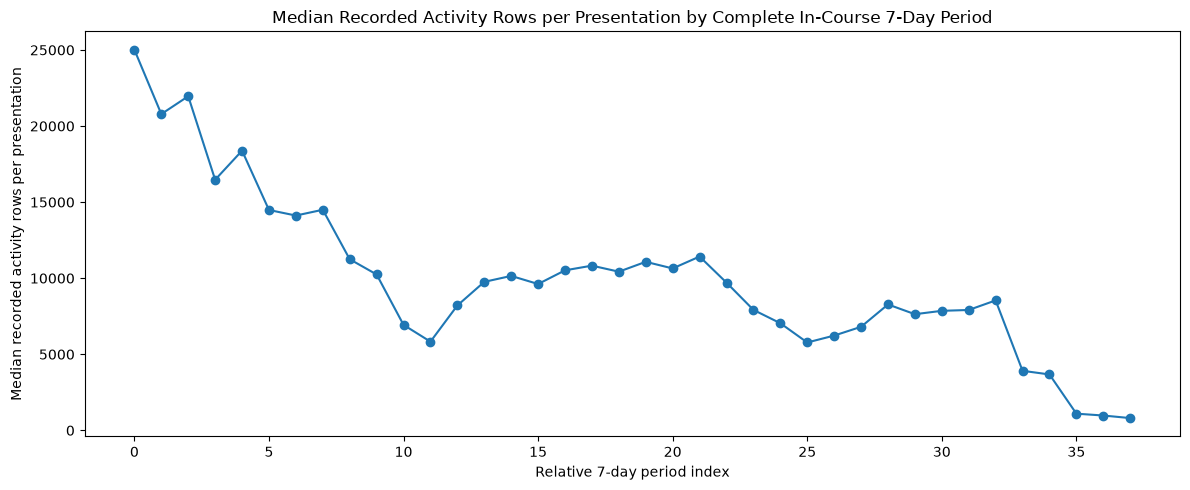

,period_index,median_activity_rows_per_presentation,presentations
0,0,25015.0,22
1,1,20787.0,22
2,2,21960.0,22
3,3,16471.0,22
4,4,18382.0,22
5,5,14483.5,22
6,6,14117.5,22
7,7,14498.0,22
8,8,11246.5,22
9,9,10245.5,22


Presentations represented: 4
Complete presentation-period observations: 795
Partial or post-course period rows excluded from this figure: 22
Interpretation: the chart compares complete seven-day periods only. It does not represent the final partial period of each course.


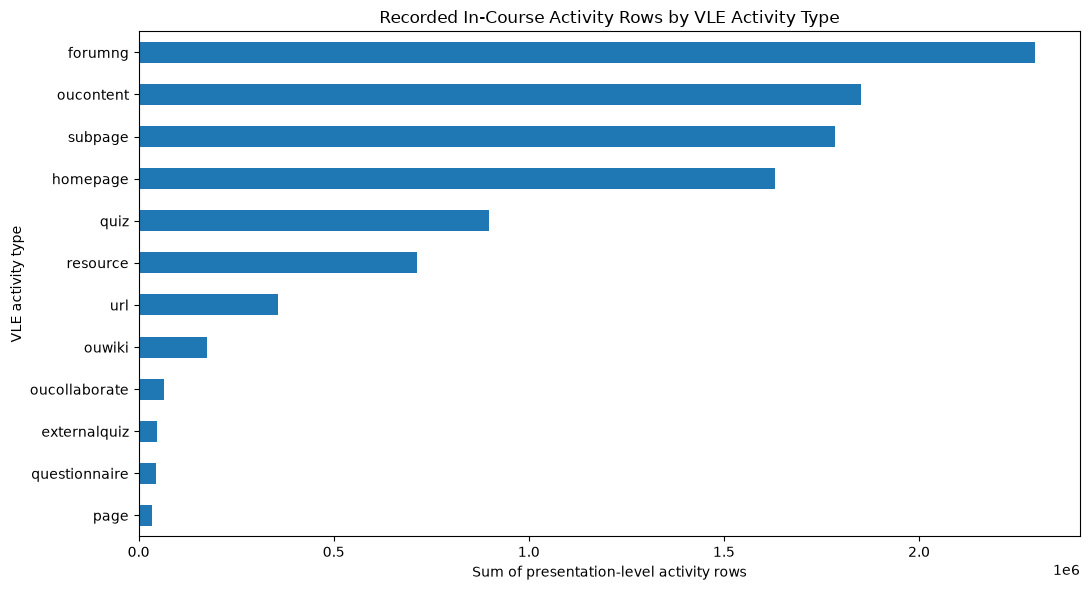

In [14]:

# 12. Plot complete in-course relative periods and activity-type composition.
# Partial final periods are excluded from this figure to avoid mixing
# in-course and post-course activity in a period that crosses the course boundary.

# 1. Retrieve the complete AN6.03 period output and AN6.01 course windows.
an603_item = query_results["AN6.03"]["result_sets"][0]
an601_courses = query_results["AN6.01"]["result_sets"][0]["data"].copy()

if an603_item["display_truncated"]:
    raise RuntimeError(
        "AN6.03 is truncated. Do not generate the temporal profile."
    )

period_profile = an603_item["data"].loc[
    an603_item["data"]["output_section"].eq("RELATIVE_7DAY_PERIOD")
].copy()

# 2. Convert period and course-window fields to numeric values.
period_profile["period_index"] = pd.to_numeric(
    period_profile["period_index"], errors="coerce"
)
period_profile["activity_rows"] = pd.to_numeric(
    period_profile["activity_rows"], errors="coerce"
)

an601_courses["module_presentation_length"] = pd.to_numeric(
    an601_courses["module_presentation_length"], errors="coerce"
)

# Keep only non-negative relative periods.
period_profile = period_profile.loc[
    period_profile["period_index"].notna()
    & period_profile["period_index"].ge(0)
].copy()

period_profile["period_index"] = period_profile["period_index"].astype(int)

# 3. Attach the presentation-specific course duration.
period_profile = period_profile.merge(
    an601_courses[
        ["code_module", "code_presentation", "module_presentation_length"]
    ],
    on=["code_module", "code_presentation"],
    how="left",
    validate="many_to_one"
)

if period_profile["module_presentation_length"].isna().any():
    raise ValueError(
        "Some relative periods could not be matched to a valid course window."
    )

# 4. Retain only seven-day periods fully contained within the course.
period_profile["period_start_day"] = period_profile["period_index"] * 7
period_profile["period_end_day"] = (
    period_profile["period_start_day"] + 6
)

complete_in_course = period_profile.loc[
    period_profile["period_end_day"]
    <= period_profile["module_presentation_length"]
].copy()

if complete_in_course.empty:
    raise ValueError(
        "No complete in-course seven-day periods are available for plotting."
    )

# A complete seven-day period cannot contain post-course activity.
# There should therefore be one row per presentation and period.
period_keys = [
    "code_module",
    "code_presentation",
    "period_index"
]

if complete_in_course.duplicated(period_keys).any():
    raise ValueError(
        "Duplicate presentation-period rows found in complete in-course periods. "
        "Inspect AN6.03 temporal grouping before interpreting the chart."
    )

# 5. Calculate the median activity rows across presentations per period.
period_plot = (
    complete_in_course.groupby("period_index", as_index=False)
    .agg(
        median_activity_rows_per_presentation=("activity_rows", "median"),
        presentations=("code_presentation", "count")
    )
    .sort_values("period_index")
)

ax = period_plot.plot(
    x="period_index",
    y="median_activity_rows_per_presentation",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False,
    title=(
        "Median Recorded Activity Rows per Presentation "
        "by Complete In-Course 7-Day Period"
    )
)

ax.set_xlabel("Relative 7-day period index")
ax.set_ylabel("Median recorded activity rows per presentation")

plt.tight_layout()
plt.show()

display(period_plot)

print(
    "Presentations represented:",
    complete_in_course["code_presentation"].nunique()
)
print(
    "Complete presentation-period observations:",
    len(complete_in_course)
)
print(
    "Partial or post-course period rows excluded from this figure:",
    len(period_profile) - len(complete_in_course)
)
print(
    "Interpretation: the chart compares complete seven-day periods only. "
    "It does not represent the final partial period of each course."
)

# 6. Plot the 12 highest-volume in-course activity types.
top_types = (
    an604_type_profile.head(12)
    .sort_values("in_course_activity_rows")
)

ax = top_types.plot(
    x="activity_type",
    y="in_course_activity_rows",
    kind="barh",
    figsize=(11, 6),
    legend=False,
    title="Recorded In-Course Activity Rows by VLE Activity Type"
)

ax.set_xlabel("Sum of presentation-level activity rows")
ax.set_ylabel("VLE activity type")

plt.tight_layout()
plt.show()


## 13. AN6 — Evidence-based analytical closeout report

This final cell generates a compact report from the reviewed DataFrames and reconciliation checks. It distinguishes questions answered by AN6 from design decisions inherited from AN5, identifies incomplete checks, and carries unresolved questions into AN7. A passing status means the evidence is ready for project-lead review; it does not merge the PR or authorize the next stage automatically.

In [15]:
# 13. Generate the AN6 closeout report from validated result frames.
from IPython.display import Markdown

AN6_REVIEW_CHECKS = {
    "AN6.01 readiness": bool(AN6_READINESS_PASSED),
    "AN6.02 coverage partition": bool(AN6_02_PARTITION_PASSED),
    "AN6.03 temporal and boundary reconciliation": bool(AN6_03_RECONCILIATION_PASSED),
    "AN6.04 metadata and activity-type reconciliation": bool(AN6_04_RECONCILIATION_PASSED),
    "all result sets complete": all(
        not item["display_truncated"]
        for qid in ["AN6.01", "AN6.02", "AN6.03", "AN6.04"]
        for item in query_results[qid]["result_sets"]
    ),
}
AN6_ANALYTICAL_REVIEW_PASSED = all(AN6_REVIEW_CHECKS.values())

question_rows = [
    ("Q01–Q02", "Course windows, resource metadata, keys and join readiness",
     "ANSWERED" if AN6_READINESS_PASSED else "BLOCKED"),
    ("Q03–Q05", "In-course coverage, zero-inclusive days/resources and first activity",
     "ANSWERED" if AN6_02_PARTITION_PASSED else "REVIEW"),
    ("Q06", "PRE/IN/POST and relative seven-day activity patterns",
     "ANSWERED" if AN6_03_RECONCILIATION_PASSED else "REVIEW"),
    ("Q07", "Fixed registered cohort and survivorship limitation",
     "DESIGN ACCEPTED — NOT AN AT-RISK COHORT"),
    ("Q08", "Activity-type resource breadth and registered reach",
     "ANSWERED" if AN6_04_RECONCILIATION_PASSED else "REVIEW"),
    ("Q09", "VLE week metadata completeness",
     "ANSWERED DESCRIPTIVELY — NOT USED AS A FILTER"),
    ("Q10", "Repeated-row sensitivity requirement",
     "CARRIED FROM AN5 — NO R1/R2 RESCAN"),
    ("Q11", "Boundary and temporal-total reconciliation",
     "ANSWERED" if AN6_03_RECONCILIATION_PASSED else "REVIEW"),
]
question_table = pd.DataFrame(question_rows, columns=["Question", "Scope", "Disposition"])
temporal_totals = (
    an603_bucket.groupby("bucket_label", as_index=False)["activity_rows"].sum()
    .sort_values("activity_rows", ascending=False)
)
temporal_total = int(temporal_totals["activity_rows"].sum())
temporal_totals["share_pct"] = (
    100 * temporal_totals["activity_rows"] / temporal_total if temporal_total else 0
)
top_type_lines = "\n".join(
    f"- {row.activity_type}: {int(row.in_course_activity_rows):,} recorded in-course rows"
    for row in an604_type_profile.head(5).itertuples()
)
check_lines = "\n".join(
    f"- {'PASS' if passed else 'REVIEW REQUIRED'} — {name}"
    for name, passed in AN6_REVIEW_CHECKS.items()
)
AN6_FINAL_DISPOSITION = (
    "READY FOR PROJECT-LEAD REVIEW"
    if AN6_ANALYTICAL_REVIEW_PASSED
    else "NOT READY — FOLLOW-UP REQUIRED"
)
report = f"""# AN6 — Recorded VLE Activity Patterns: Results Review

**Disposition:** {AN6_FINAL_DISPOSITION}

## Main results

- Registered student-presentations: **{coverage_denominator:,}**.
- With in-course recorded activity: **{coverage_numerator:,}** (**{pooled_coverage_pct:.2f}%** pooled coverage).
- Outside-window-only registrations: **{outside_only_total:,}**.
- Registrations with no recorded activity in any observed window: **{no_activity_total:,}**.
- Activity rows reconciled across temporal buckets and relative periods: **{bucket_activity_total:,}**.
- Resource metadata rows: **{metadata_matched_rows:,} matched**, **{metadata_unmatched_rows:,} unmatched**, out of **{metadata_all_rows:,}**.
- Activity rows with missing activity_type: **{metadata_missing_type_rows:,}**.
- Unmatched-registration activity rows: **{metadata_unmatched_registration_rows:,}**.

## Temporal distribution

{temporal_totals.to_string(index=False)}

## Highest-volume in-course activity types

{top_type_lines}

## AN6 question disposition

{question_table.to_string(index=False)}

## Acceptance checks

{check_lines}

## New questions and limitations carried forward

1. **VLE week metadata:** 5,243 of 6,364 resource records have missing week_from, and 5,243 have missing week_to. If academic-week reporting is required, assess the overlap and distribution by presentation and resource type; current course-relative measures do not depend on these fields.
2. **Post-course activity:** preserve it as recorded platform activity. Its administrative or pedagogical meaning is not established by these queries.
3. **Fixed-cohort limitation:** the registered denominator is not a time-varying at-risk population. Do not infer exposure duration or survival from this design.
4. **Activity-type overlap:** one student-presentation can use several activity types. Reach totals across types are non-additive and must not be treated as unique learners.
5. **Recorded-activity boundary:** no VLE row means no matching recorded row under the specified key and window, not absence of learning.

## AN7 dependencies

AN7 may examine descriptive associations between accepted AN6 measures and outcomes only after its outcome and time rules are frozen. The handoff must address:
- the conflict between final_result and date_unregistration (WO-2 OQ-03);
- the unresolved meaning and valid use of is_banked (WO-2 OQ-06);
- assessment-weight coverage and score-definition limitations (WO-2 OQ-07);
- CMA due-date semantics and the distinction between recorded due dates and valid lateness;
- a leakage-safe cutoff and feature window, with no retrospective outcome fields used as predictors.

AN6 does not establish causality, learning quality, a composite score, threshold, intervention rule, or predictive feature. RAW, QUALITY and STAGING remain unchanged.

**Review boundary:** this report is generated from retained query result frames. It does not itself close AN6, merge PR #16, or authorize AN7.
"""
display(Markdown(report))
print("AN6_ANALYTICAL_REVIEW_PASSED:", AN6_ANALYTICAL_REVIEW_PASSED)


# AN6 — Recorded VLE Activity Patterns: Results Review

**Disposition:** READY FOR PROJECT-LEAD REVIEW

## Main results

- Registered student-presentations: **32,593**.
- With in-course recorded activity: **28,500** (**87.44%** pooled coverage).
- Outside-window-only registrations: **728**.
- Registrations with no recorded activity in any observed window: **3,365**.
- Activity rows reconciled across temporal buckets and relative periods: **10,655,280**.
- Resource metadata rows: **10,655,280 matched**, **0 unmatched**, out of **10,655,280**.
- Activity rows with missing activity_type: **0**.
- Unmatched-registration activity rows: **0**.

## Temporal distribution

bucket_label  activity_rows  share_pct
   IN_COURSE        9966292  93.533835
  PRE_COURSE         688988   6.466165

## Highest-volume in-course activity types

- forumng: 2,297,748 recorded in-course rows
- oucontent: 1,850,375 recorded in-course rows
- subpage: 1,783,734 recorded in-course rows
- homepage: 1,630,668 recorded in-course rows
- quiz: 897,842 recorded in-course rows

## AN6 question disposition

Question                                                                Scope                                   Disposition
 Q01–Q02           Course windows, resource metadata, keys and join readiness                                      ANSWERED
 Q03–Q05 In-course coverage, zero-inclusive days/resources and first activity                                      ANSWERED
     Q06                 PRE/IN/POST and relative seven-day activity patterns                                      ANSWERED
     Q07                  Fixed registered cohort and survivorship limitation       DESIGN ACCEPTED — NOT AN AT-RISK COHORT
     Q08                  Activity-type resource breadth and registered reach                                      ANSWERED
     Q09                                       VLE week metadata completeness ANSWERED DESCRIPTIVELY — NOT USED AS A FILTER
     Q10                                 Repeated-row sensitivity requirement            CARRIED FROM AN5 — NO R1/R2 RESCAN
     Q11                           Boundary and temporal-total reconciliation                                      ANSWERED

## Acceptance checks

- PASS — AN6.01 readiness
- PASS — AN6.02 coverage partition
- PASS — AN6.03 temporal and boundary reconciliation
- PASS — AN6.04 metadata and activity-type reconciliation
- PASS — all result sets complete

## New questions and limitations carried forward

1. **VLE week metadata:** 5,243 of 6,364 resource records have missing week_from, and 5,243 have missing week_to. If academic-week reporting is required, assess the overlap and distribution by presentation and resource type; current course-relative measures do not depend on these fields.
2. **Post-course activity:** preserve it as recorded platform activity. Its administrative or pedagogical meaning is not established by these queries.
3. **Fixed-cohort limitation:** the registered denominator is not a time-varying at-risk population. Do not infer exposure duration or survival from this design.
4. **Activity-type overlap:** one student-presentation can use several activity types. Reach totals across types are non-additive and must not be treated as unique learners.
5. **Recorded-activity boundary:** no VLE row means no matching recorded row under the specified key and window, not absence of learning.

## AN7 dependencies

AN7 may examine descriptive associations between accepted AN6 measures and outcomes only after its outcome and time rules are frozen. The handoff must address:
- the conflict between final_result and date_unregistration (WO-2 OQ-03);
- the unresolved meaning and valid use of is_banked (WO-2 OQ-06);
- assessment-weight coverage and score-definition limitations (WO-2 OQ-07);
- CMA due-date semantics and the distinction between recorded due dates and valid lateness;
- a leakage-safe cutoff and feature window, with no retrospective outcome fields used as predictors.

AN6 does not establish causality, learning quality, a composite score, threshold, intervention rule, or predictive feature. RAW, QUALITY and STAGING remain unchanged.

**Review boundary:** this report is generated from retained query result frames. It does not itself close AN6, merge PR #16, or authorize AN7.


AN6_ANALYTICAL_REVIEW_PASSED: True
